<a href="https://colab.research.google.com/github/jaswanth424/MachineLearning/blob/main/used_vehicle_on_schedule_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###SENECA POLYTECHNIC  
###MASTER OF ARTIFICIAL INTELLIGENCE DESIGN & DEVELOPMENT

Submitted To: Prof. Reid Kerr  
Submitted By: Jaswanth Kumar Reddy Chittem
Course: Machine Learning  
Course Code: MAI101

Submission Date: October 27, 2026



# Predicting Whether Used Vehicles Sell on Schedule
**Classification assignment | Ontario used-vehicle dealership**

## Objective
Build and compare at least three classification models to predict whether a listed vehicle will sell on schedule, using only information available when it is prepared for sale.

**Important leakage control:** `LISTING_DAYS` and `SELLING_PRICE` are used only to construct the target and are excluded from predictors. `LISTING_DAYS` is not known at prediction time, and `SELLING_PRICE` is the outcome used to identify a successful sale.

## 1. Exploratory data analysis

Load the dataset and inspect its size, data types, missing values, body-type distribution, listing duration, selling outcomes, and the derived target. The target rule uses the supplied body-type SLA: `on_schedule` when a vehicle sold (non-missing `SELLING_PRICE`) and `LISTING_DAYS <= 2 × target_days + 2`; unsold vehicles are not on schedule.

For sold vehicles with missing `LISTING_DAYS`, or sold vehicles whose `BODY_TYPE` has no SLA mapping, the target cannot be determined reliably. Those rows are excluded from model training rather than assigning an arbitrary label. An unsold vehicle is labeled 0 even if its listing duration is missing.

In [17]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


csv_path = "used_vehicle_data.csv"

df = pd.read_csv(csv_path)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 1,815 rows × 18 columns


,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
0,Mercedes-Benz,GLA,2010,193254.0,1.8,Gasoline,Automatic,Sedan,AWD,4.0,5.0,0.0,2.0,Red,40.0,0.0,7.0,39257.66
1,Nissan,Frontier,2021,58800.0,5.7,Gasoline,Automatic,SUV,FWD,4.0,5.0,1.0,3.0,Black,71.0,0.0,2.0,42237.72
2,Hyundai,Palisade,2017,127591.0,2.0,Hybrid,Dual-Clutch,SUV,AWD,5.0,6.0,1.0,1.0,Brown,23.0,0.0,7.0,45240.28
3,BMW,X3,2015,170698.0,2.5,Gasoline,Automatic,Sedan,4WD,4.0,7.0,1.0,2.0,Silver,94.0,0.0,9.0,46287.33
4,Honda,Accord,2022,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51


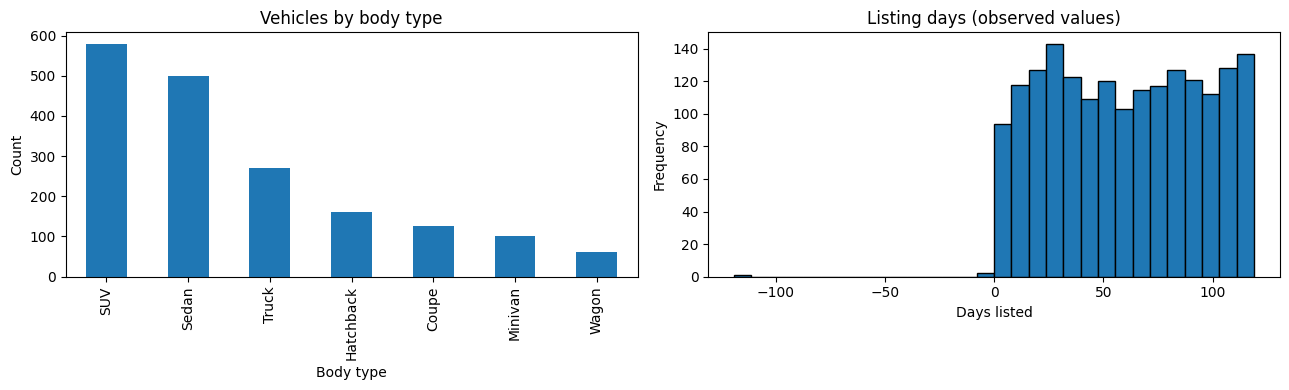

In [18]:
# print("Data types and non-null counts:")
# display(pd.DataFrame({
#     "dtype": df.dtypes.astype(str),
#     "non_missing": df.notna().sum(),
#     "missing": df.isna().sum(),
#     "missing_%": (df.isna().mean() * 100).round(1)
# }).sort_values("missing", ascending=False))

# print("\nBody-type counts (including missing):")
# display(df["BODY_TYPE"].value_counts(dropna=False).rename_axis("BODY_TYPE").to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["BODY_TYPE"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Vehicles by body type")
axes[0].set_xlabel("Body type")
axes[0].set_ylabel("Count")
df["LISTING_DAYS"].dropna().plot(kind="hist", bins=30, ax=axes[1], edgecolor="black")
axes[1].set_title("Listing days (observed values)")
axes[1].set_xlabel("Days listed")
plt.tight_layout()
plt.show()

### Create the binary target

The target is created from the original outcome columns using the exact rule in the assignment. Unknown body types and missing listing durations are not silently treated as on-schedule sales.

Rows in original dataset: 1,815
Rows excluded because target is indeterminate: 36
Rows available for modelling: 1,779

Target distribution:


,count
ON_SCHEDULE,
On schedule,1478
Not on schedule,301


,percent
ON_SCHEDULE,
On schedule,83.1
Not on schedule,16.9


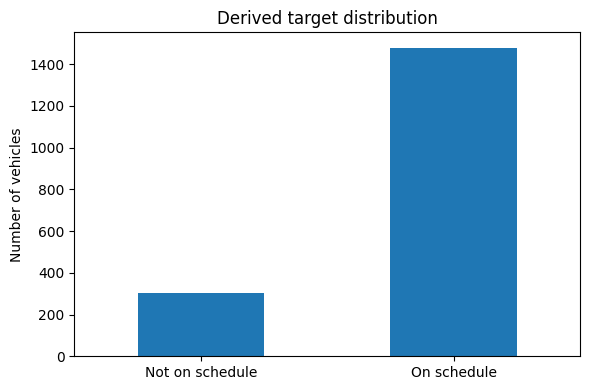

In [19]:
target_days = {
    "Hatchback": 40,
    "Sedan": 45,
    "SUV": 50,
    "Minivan": 50,
    "Truck": 55,
    "Coupe": 60,
    "Wagon": 65
}

df["TARGET_DAYS"] = df["BODY_TYPE"].map(target_days)
df["SCHEDULE_CUTOFF"] = 2 * df["TARGET_DAYS"] + 2

# Start with unknown target; then apply cases that can be determined.
df["ON_SCHEDULE"] = np.nan
unsold = df["SELLING_PRICE"].isna()
df.loc[unsold, "ON_SCHEDULE"] = 0

sold_and_classifiable = (
    df["SELLING_PRICE"].notna()
    & df["LISTING_DAYS"].notna()
    & df["TARGET_DAYS"].notna()
)
df.loc[sold_and_classifiable, "ON_SCHEDULE"] = (
    df.loc[sold_and_classifiable, "LISTING_DAYS"]
    <= df.loc[sold_and_classifiable, "SCHEDULE_CUTOFF"]
).astype(int)

n_unknown_target = int(df["ON_SCHEDULE"].isna().sum())
model_df = df.loc[df["ON_SCHEDULE"].notna()].copy()
model_df["ON_SCHEDULE"] = model_df["ON_SCHEDULE"].astype(int)

print(f"Rows in original dataset: {len(df):,}")
print(f"Rows excluded because target is indeterminate: {n_unknown_target:,}")
print(f"Rows available for modelling: {len(model_df):,}")
print("\nTarget distribution:")
display(model_df["ON_SCHEDULE"].value_counts().rename(index={0: "Not on schedule", 1: "On schedule"}).to_frame("count"))
display((model_df["ON_SCHEDULE"].value_counts(normalize=True) * 100).round(1).rename(index={0: "Not on schedule", 1: "On schedule"}).to_frame("percent"))

ax = model_df["ON_SCHEDULE"].value_counts().sort_index().rename(index={0:"Not on schedule",1:"On schedule"}).plot(
    kind="bar", figsize=(6,4), rot=0, title="Derived target distribution"
)
ax.set_xlabel("")
ax.set_ylabel("Number of vehicles")
plt.tight_layout()
plt.show()

### EDA findings (complete after running)

Use the output above to report the target class balance, number of indeterminate rows removed, missing-data pattern, and body types represented. If classes are imbalanced, do not rely on accuracy alone; compare precision, recall, F1, ROC-AUC, and confusion matrices. The target is an operational definition based on the assignment's SLA, not a claim that all vehicles have the same sales process.

## 2. Data preparation

- **Target construction:** apply the body-type SLA plus the specified doubled baseline and two-day leeway.
- **Indeterminate labels:** exclude only rows where the target cannot be determined (sold, but listing days are missing, or SLA/body type is unavailable). Rows with missing selling price are labeled not on schedule.
- **Train/test separation:** split before fitting preprocessing, using stratification to preserve the target class ratio.
- **Leakage prevention:** remove `LISTING_DAYS`, `SELLING_PRICE`, and helper columns (`TARGET_DAYS`, `SCHEDULE_CUTOFF`, `ON_SCHEDULE`) from the feature matrix.
- **Preprocessing fit:** imputers, scaler, and one-hot encoder are inside an sklearn pipeline, so they are fitted only on training data. The held-out test set is used for final comparison, not for fitting.

In [20]:
# Only features known when the vehicle is prepared for sale.
excluded = ["LISTING_DAYS", "SELLING_PRICE", "TARGET_DAYS", "SCHEDULE_CUTOFF", "ON_SCHEDULE"]
X = model_df.drop(columns=excluded)
y = model_df["ON_SCHEDULE"]

# Treat object/category columns as categorical; remaining fields are numeric.
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Predictor columns:")
print(X.columns.tolist())
print("\nCategorical predictors:", categorical_features)
print("Numeric predictors:", numeric_features)
print("\nLeakage check:")
assert "LISTING_DAYS" not in X.columns
assert "SELLING_PRICE" not in X.columns
print("PASS: LISTING_DAYS and SELLING_PRICE are not predictors.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,  stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Training positive rate: {y_train.mean():.3f}; test positive rate: {y_test.mean():.3f}")

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Predictor columns:
['MAKE', 'MODEL', 'YEAR', 'KILOMETRES', 'ENGINE_SIZE', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE', 'DRIVETRAIN', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'COLOUR', 'HAS_WARRANTY', 'CONDITION_SCORE']

Categorical predictors: ['MAKE', 'MODEL', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE', 'DRIVETRAIN', 'COLOUR']
Numeric predictors: ['YEAR', 'KILOMETRES', 'ENGINE_SIZE', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'HAS_WARRANTY', 'CONDITION_SCORE']

Leakage check:
PASS: LISTING_DAYS and SELLING_PRICE are not predictors.
Training rows: 1,423; test rows: 356
Training positive rate: 0.831; test positive rate: 0.831


## 3. Model

Three classification algorithms are compared: `Logistic Regression` (linear baseline), `Decision Tree` (non-linear, interpretable rule-based model), and `Random Forest` (ensemble of trees). All models use the same stratified 80/20 split and preprocessing pipeline. No hyperparameter search is performed, as specified in the assignment.


Logistic Regression
Estimator details:
LogisticRegression(class_weight='balanced', max_iter=2000)

Classification report:
                     precision    recall  f1-score   support

Not on schedule (0)       0.23      0.50      0.32        60
    On schedule (1)       0.87      0.67      0.75       296

           accuracy                           0.64       356
          macro avg       0.55      0.58      0.54       356
       weighted avg       0.76      0.64      0.68       356



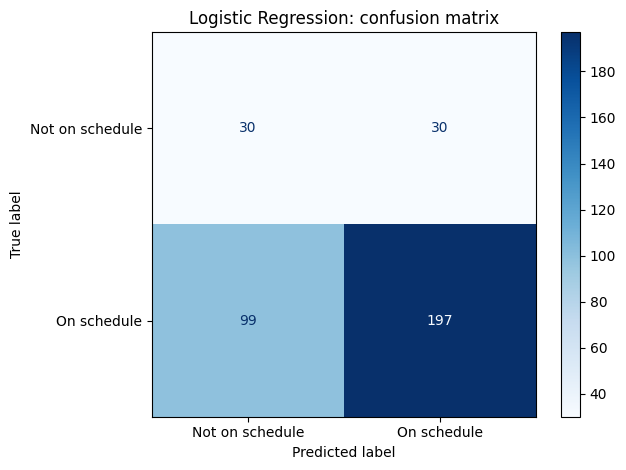


Decision Tree
Estimator details:
DecisionTreeClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=5)

Classification report:
                     precision    recall  f1-score   support

Not on schedule (0)       0.21      0.75      0.33        60
    On schedule (1)       0.90      0.44      0.59       296

           accuracy                           0.49       356
          macro avg       0.55      0.59      0.46       356
       weighted avg       0.78      0.49      0.55       356



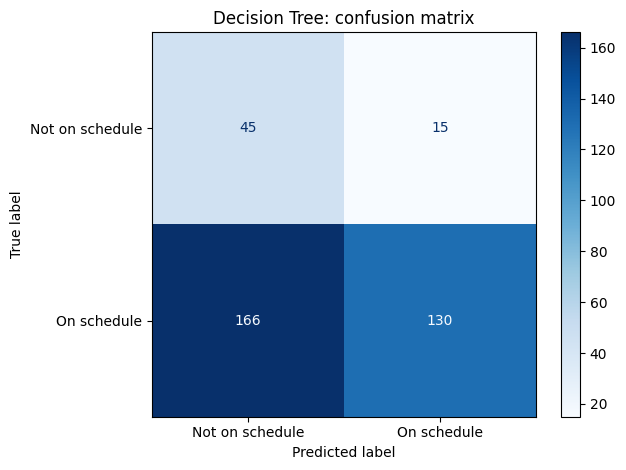


Random Forest
Estimator details:
RandomForestClassifier(class_weight='balanced', min_samples_leaf=3,
                       n_estimators=300, n_jobs=-1)

Classification report:
                     precision    recall  f1-score   support

Not on schedule (0)       0.29      0.27      0.28        60
    On schedule (1)       0.85      0.86      0.86       296

           accuracy                           0.76       356
          macro avg       0.57      0.57      0.57       356
       weighted avg       0.76      0.76      0.76       356



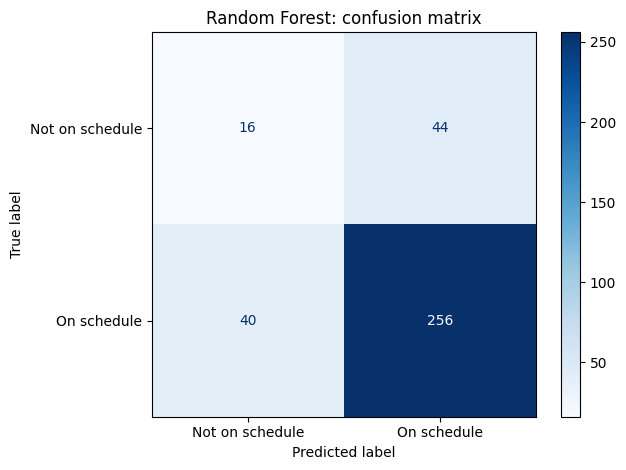

Held-out test-set metrics (higher is better for all listed metrics):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.764,0.853,0.865,0.859,0.657
1,Logistic Regression,0.638,0.868,0.666,0.753,0.644
2,Decision Tree,0.492,0.897,0.439,0.590,0.619


In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=5, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced", n_jobs=-1
    )
}

pipelines = {}
results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    }
    results.append(metrics)

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)
    print("Estimator details:")
    print(pipe.named_steps["classifier"])
    print("\nClassification report:")
    print(classification_report(
        y_test, pred, target_names=["Not on schedule (0)", "On schedule (1)"],
        zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Not on schedule", "On schedule"], cmap="Blues"
    )
    plt.title(f"{name}: confusion matrix")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
print("Held-out test-set metrics (higher is better for all listed metrics):")
display(results_df.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "F1": "{:.3f}", "ROC-AUC": "{:.3f}"
}))

### ROC curves

ROC-AUC measures how well the model ranks positive cases above negative cases across classification thresholds. It complements threshold-based measures and should be interpreted alongside precision, recall, F1, and the confusion matrix.

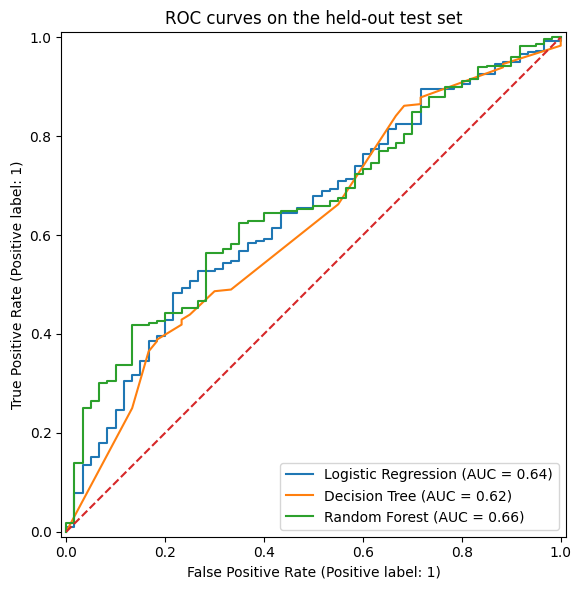

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC curves on the held-out test set")
plt.tight_layout()
plt.show()

## 4. Evaluation and model selection

The primary selection criterion here is **F1-score for the `ON_SCHEDULE = 1` class**, because the task is to identify on-schedule sales and a balance between precision and recall is useful. ROC-AUC is a secondary ranking metric; the business should also consider whether missing an on-schedule vehicle or incorrectly predicting one is more costly. The final selection must be based on the held-out test results printed below, not on training performance.

In [23]:
best_row = results_df.iloc[0]
best_name = best_row["Model"]
best_pipe = fitted_models[best_name]
best_pred = best_pipe.predict(X_test)

print(f"Selected model by test F1: {best_name}")
print("Metrics:")
display(results_df.loc[results_df["Model"] == best_name].style.format("{:.3f}", subset=["Accuracy","Precision","Recall","F1","ROC-AUC"]))
print("\nInterpretation:")
print(
    f"The selected model has F1={best_row['F1']:.3f}, "
    f"precision={best_row['Precision']:.3f}, recall={best_row['Recall']:.3f}, "
    f"and ROC-AUC={best_row['ROC-AUC']:.3f} on the held-out test set."
)
print("\nFinal classification report:")
print(classification_report(
    y_test, best_pred, target_names=["Not on schedule (0)", "On schedule (1)"],
    zero_division=0
))

Selected model by test F1: Random Forest
Metrics:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.764,0.853,0.865,0.859,0.657



Interpretation:
The selected model has F1=0.859, precision=0.853, recall=0.865, and ROC-AUC=0.657 on the held-out test set.

Final classification report:
                     precision    recall  f1-score   support

Not on schedule (0)       0.29      0.27      0.28        60
    On schedule (1)       0.85      0.86      0.86       296

           accuracy                           0.76       356
          macro avg       0.57      0.57      0.57       356
       weighted avg       0.76      0.76      0.76       356



### Model reflection and limitations

Complete the interpretation using the results above:

- **Best model:** Random forest is the best model selected by the chosen F1 criterion and quote its F1, precision, recall, and ROC-AUC.
- **Error trade-off:** use its confusion matrix and precision/recall to explain whether it misses many on-schedule vehicles (false negatives) or incorrectly flags not-on-schedule vehicles (false positives).
- **Practical meaning:** these models estimate the probability of meeting an operational SLA from the vehicle's preparation-time characteristics; they do not establish causation.
- **Limitations:** the data may be synthetic or reflect only a limited dealership and period; the SLA is a rule-based target; missing labels were excluded; a single train/test split can vary with the random seed. Before deployment, validate on later listings and consider the business costs of the two error types.